In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, os, math, datetime
from sklearn.linear_model import LinearRegression
from Metrics.CrossValidation.index import CrossValidation
from Metrics.Plotter.index import Plotter
pd.set_option('display.max_columns', None)

In [2]:
TEST    = json.loads(open('../../info.json', 'r').read()).get('test', 1)
RESULTS = f'../../Dataset/test{TEST}/results'
SOURCE  = f'{RESULTS}/corrected.csv'

print('SOURCE:', SOURCE)

SOURCE: ../../Dataset/test1/results/corrected.csv


# IMPORTANDO DADOS
- Saída do `2 - Correction`: os ângulos que o próprio Kernel calcula, nos eixos dele e na escala do ICD, ao lado da atitude da referência

In [3]:
ANGLES = ['pitch', 'roll', 'yaw']

df = pd.read_csv(SOURCE)
df = df[['time', 'static'] + ANGLES + [f'ref_{var}' for var in ANGLES]]
dt = round(float(df.time.diff().median()), 3)
df

,time,static,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw
0,0.0,False,18.043,1.525,2.936,0.304871,-71.390541,2.771970
1,0.1,False,12.732,0.742,2.725,0.337243,-76.661753,2.723841
2,0.2,False,6.586,-0.119,2.578,0.366750,-82.677810,2.667691
3,0.3,False,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322
4,0.4,False,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...
1795,279.4,True,-2.510,-1.368,5.289,1.644962,-92.131613,6.371291
1796,279.5,True,-2.509,-1.368,5.289,1.645535,-92.131613,6.371291
1797,279.6,True,-2.506,-1.367,5.291,1.644962,-92.131613,6.371291
1798,279.7,True,-2.506,-1.367,5.289,1.645535,-92.131613,6.377020


# VISUALIZAÇÃO DOS DADOS

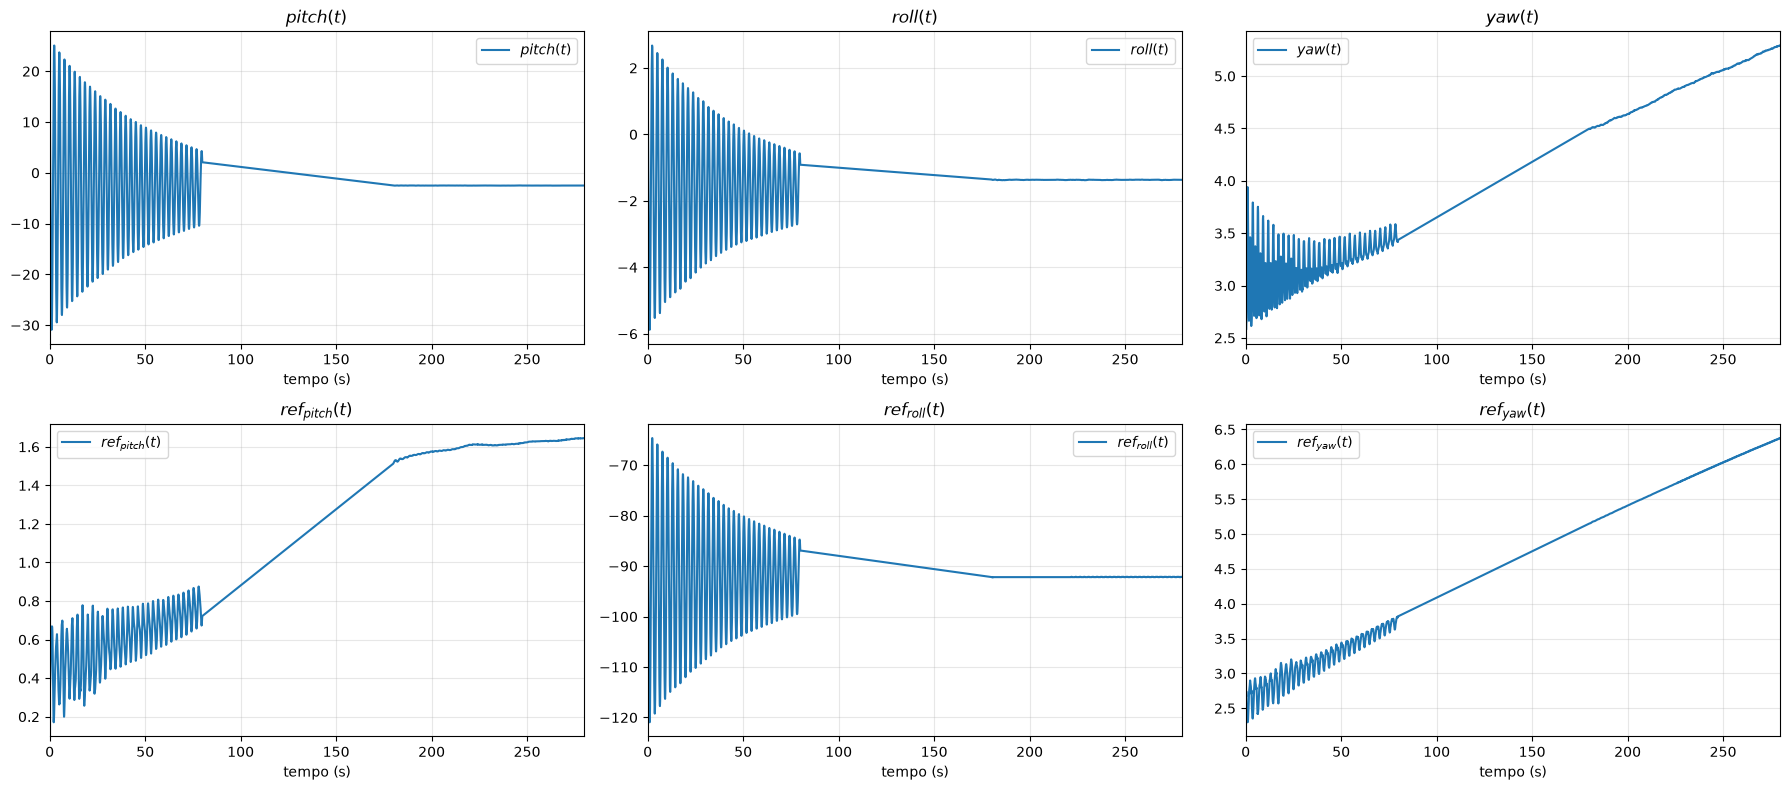

In [4]:
# GRADE DE SUBPLOTS RECORTADA POR FRAÇÃO DO TEMPO TOTAL
def compareAxis(time, data, limits=(0, 1), yLim=None):
    t_min, t_max = time.min(), time.max()
    delta = (t_max - t_min)

    start_time = t_min + (delta * limits[0])
    end_time   = t_min + (delta * limits[1])

    count   = len(data.keys())
    numCols = 3 if count >= 3 else count
    numRows = math.ceil(count / numCols)
    plt.figure(figsize=(6*numCols, 4*numRows))

    for i, (key, values) in enumerate(data.items()):
        mask = (time >= start_time) & (time <= end_time)

        plt.subplot(numRows, numCols, i+1)
        plt.plot(time[mask], values[mask], label=key)

        plt.xlim(start_time, end_time)
        if yLim: plt.ylim(yLim)
        plt.title(key); plt.xlabel('tempo (s)')
        plt.grid(alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()


# PAINEL PADRÃO: OS ÂNGULOS DO SENSOR E OS DA REFERÊNCIA
def plotAll(df, limits=(0, 1)):
    compareAxis(df.time, {
        '$pitch(t)$': df.pitch, '$roll(t)$': df.roll, '$yaw(t)$': df.yaw,
        '$ref_{pitch}(t)$': df.ref_pitch, '$ref_{roll}(t)$': df.ref_roll, '$ref_{yaw}(t)$': df.ref_yaw
    }, limits)


plotAll(df, limits=(0, 1))

In [5]:
xCols = ANGLES
yCols = [f'ref_{var}' for var in ANGLES]

full = df
df   = full.loc[~full.static]    # O AJUSTE SÓ VÊ O BALANÇO; O REPOUSO VOLTA NA HORA DE SALVAR

df

,time,static,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw
0,0.0,False,18.043,1.525,2.936,0.304871,-71.390541,2.771970
1,0.1,False,12.732,0.742,2.725,0.337243,-76.661753,2.723841
2,0.2,False,6.586,-0.119,2.578,0.366750,-82.677810,2.667691
3,0.3,False,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322
4,0.4,False,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...
795,79.5,False,4.234,-0.571,3.426,0.672652,-84.797754,3.813607
796,79.6,False,4.281,-0.571,3.422,0.674944,-84.740458,3.810742
797,79.7,False,3.920,-0.634,3.416,0.688695,-85.084233,3.803294
798,79.8,False,3.169,-0.747,3.432,0.702446,-85.829078,3.818764


# CORRELAÇÃO COM A REFERÊNCIA
- Cada ângulo do sensor contra o mesmo ângulo da referência: o ajuste por eixo só serve onde a nuvem é uma reta

/tmp/ipykernel_92551/93330830.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.grid(alpha=.3); plt.legend()


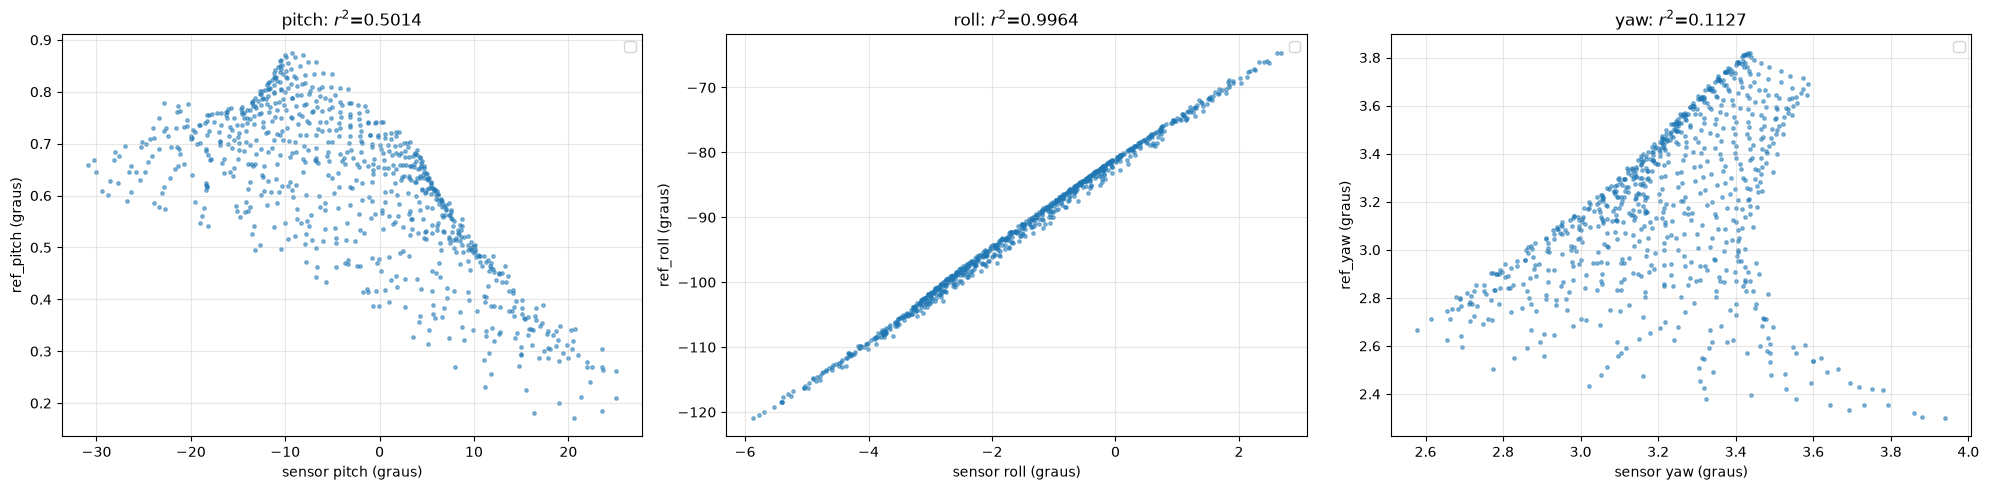

In [6]:
plt.figure(figsize=(20, 5))

for i, (xCol, yCol) in enumerate(zip(xCols, yCols)):
    corr = np.corrcoef(df[xCol], df[yCol])[0, 1]
    plt.subplot(1, 3, i + 1)
    plt.scatter(df[xCol], df[yCol], s=6, alpha=.5)

    plt.title(f'{xCol}: $r^2$={corr**2:.4f}'); plt.xlabel(f'sensor {xCol} (graus)'); plt.ylabel(f'{yCol} (graus)')
    plt.grid(alpha=.3); plt.legend()

plt.tight_layout()
plt.show()

# AJUSTE LINEAR
Cada ângulo da referência é uma combinação linear dos ângulos do sensor, ajustada por mínimos quadrados:

$$\hat{y} = M\,x + B, \qquad x = [\,pitch,\ roll,\ yaw\,]^\top$$

- **Por eixo** ($M$ diagonal): escala e viés de cada ângulo, a calibração clássica
- **Matriz cheia** ($M$ 3×3): também o acoplamento entre eixos que a montagem desalinhada cria
- O R² vem da validação cruzada em blocos contíguos intercalados, a mesma do MachineLearning: toda dobra testa balanço e repouso

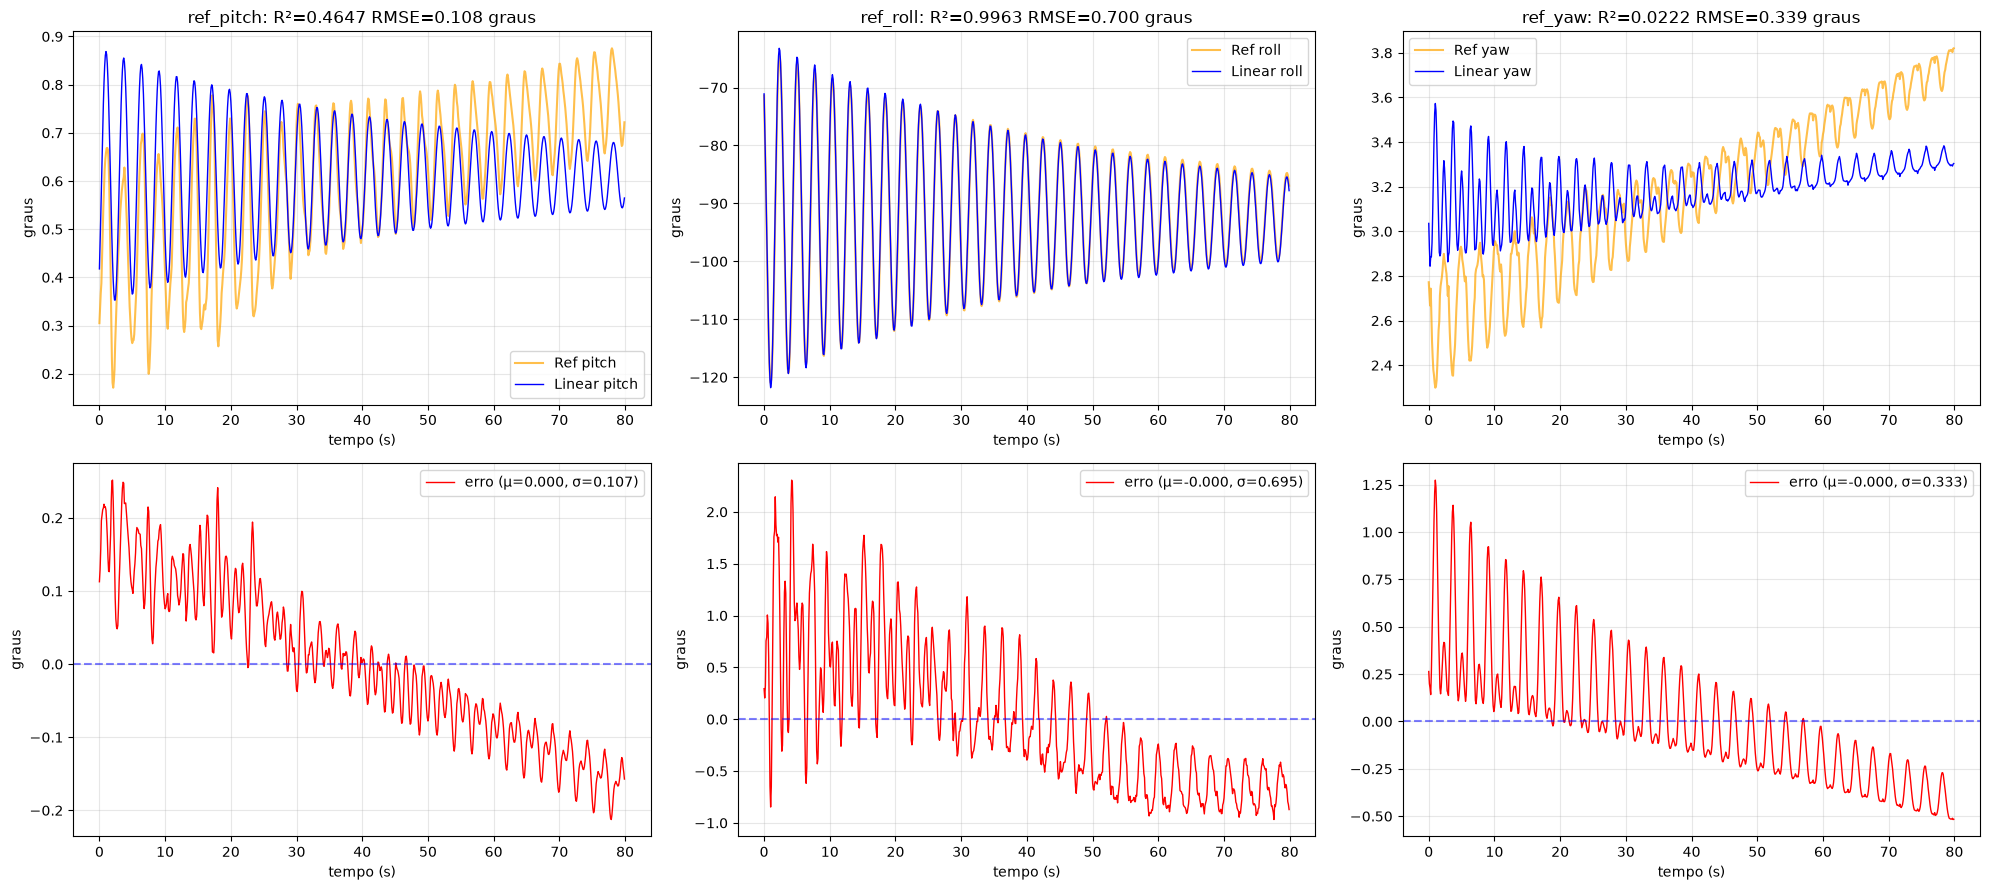

In [7]:
class LinearFit:
    K_CV = 5 

    def __init__(self, df, xCols, yCols, fuse=False):
        self.df    = df
        self.xCols = xCols
        self.yCols = yCols
        self.fuse  = fuse

    def update(self):
        size   = len(self.xCols)
        self.M = np.zeros((size, size))
        self.B = np.zeros(size)
        self.cross = {}

        for i, yCol in enumerate(self.yCols):
            inputs = list(range(size)) if self.fuse else [i]
            xData  = self.df[[self.xCols[j] for j in inputs]]
            yData  = self.df[yCol].to_numpy()

            model = LinearRegression().fit(xData, yData)
            self.M[i, inputs] = model.coef_
            self.B[i]         = model.intercept_

            self.cross[yCol] = CrossValidation(model, xData, yData, self.K_CV)
            self.cross[yCol].update()

        self.yModel = self.df[self.xCols].to_numpy() @ self.M.T + self.B
        self.errors = self.yModel - self.df[self.yCols].to_numpy()

    def get(self):
        return {yCol: cross.info() for yCol, cross in self.cross.items()}

    def info(self):
        return {yCol: {**dict(zip(self.xCols, self.M[i].round(6).tolist())), 'bias': round(float(self.B[i]), 6)} for i, yCol in enumerate(self.yCols)}

    def display(self):
        display(pd.DataFrame(self.info()).T.join(pd.DataFrame(self.get()).T))

    def plot(self, save=None):
        plt.figure(figsize=(20, 9))
        metrics = self.get()
        step    = self.df.time.diff()
        time    = self.df.time.mask(step > 1.5*step.median())    # NaN NO BURACO: A LINHA NÃO LIGA 80 s A 180 s

        for i, (xCol, yCol) in enumerate(zip(self.xCols, self.yCols)):
            error = self.errors[:, i]

            plt.subplot(2, 3, i + 1)
            plt.plot(time, self.df[yCol], label=f'Ref {xCol}', color='orange', alpha=.7)
            plt.plot(time, self.yModel[:, i], label=f'Linear {xCol}', color='blue', linewidth=1)
            plt.title(f'{yCol}: R²={metrics[yCol]["r2"]:.4f} RMSE={metrics[yCol]["rmse"]:.3f} graus')
            plt.xlabel('tempo (s)'); plt.ylabel('graus'); plt.grid(alpha=.3); plt.legend()

            plt.subplot(2, 3, i + 4)
            plt.plot(time, error, label=f'erro (µ={error.mean():.3f}, σ={error.std():.3f})', color='red', linewidth=1)
            plt.axhline(0, color='blue', linestyle='--', alpha=.5)
            plt.xlabel('tempo (s)'); plt.ylabel('graus'); plt.grid(alpha=.3); plt.legend()

        plt.tight_layout()
        if save: plt.savefig(save, dpi=110, bbox_inches='tight')
        plt.show()


fit = LinearFit(df, xCols, yCols)
fit.update()
fit.plot()

# ESCOLHA DO AJUSTE
- A matriz cheia só fica se ganhar no R² médio da validação cruzada

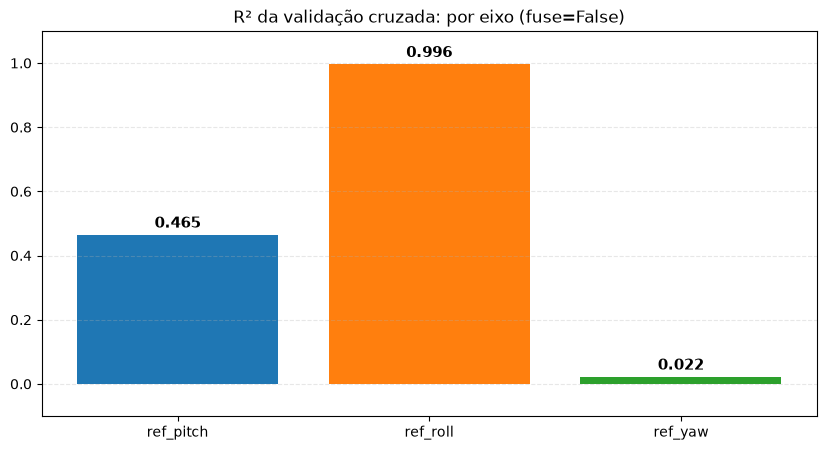

In [8]:
fit = LinearFit(df, xCols, yCols, fuse=False)
fit.update()

score = {yCol: metric['r2'] for yCol, metric in fit.get().items()}
bottom = min(0, *score.values()) - 0.1

plt.figure(figsize=(10, 5)) 
Plotter(score, limits=(bottom, 1.1), title='R² da validação cruzada: por eixo (fuse=False)')
plt.show()

# VISUALIZAÇÃO FINAL

,pitch,roll,yaw,bias,r2,r2_adj,rmse,mae
ref_pitch,-0.009221,0.000000,0.000000,0.583867,0.464683,0.461295,0.108289,0.090494
ref_roll,0.000000,6.847054,0.000000,-81.537613,0.996267,0.996244,0.699680,0.579226
ref_yaw,0.000000,0.000000,0.535418,1.463621,0.022181,0.015992,0.339230,0.260603


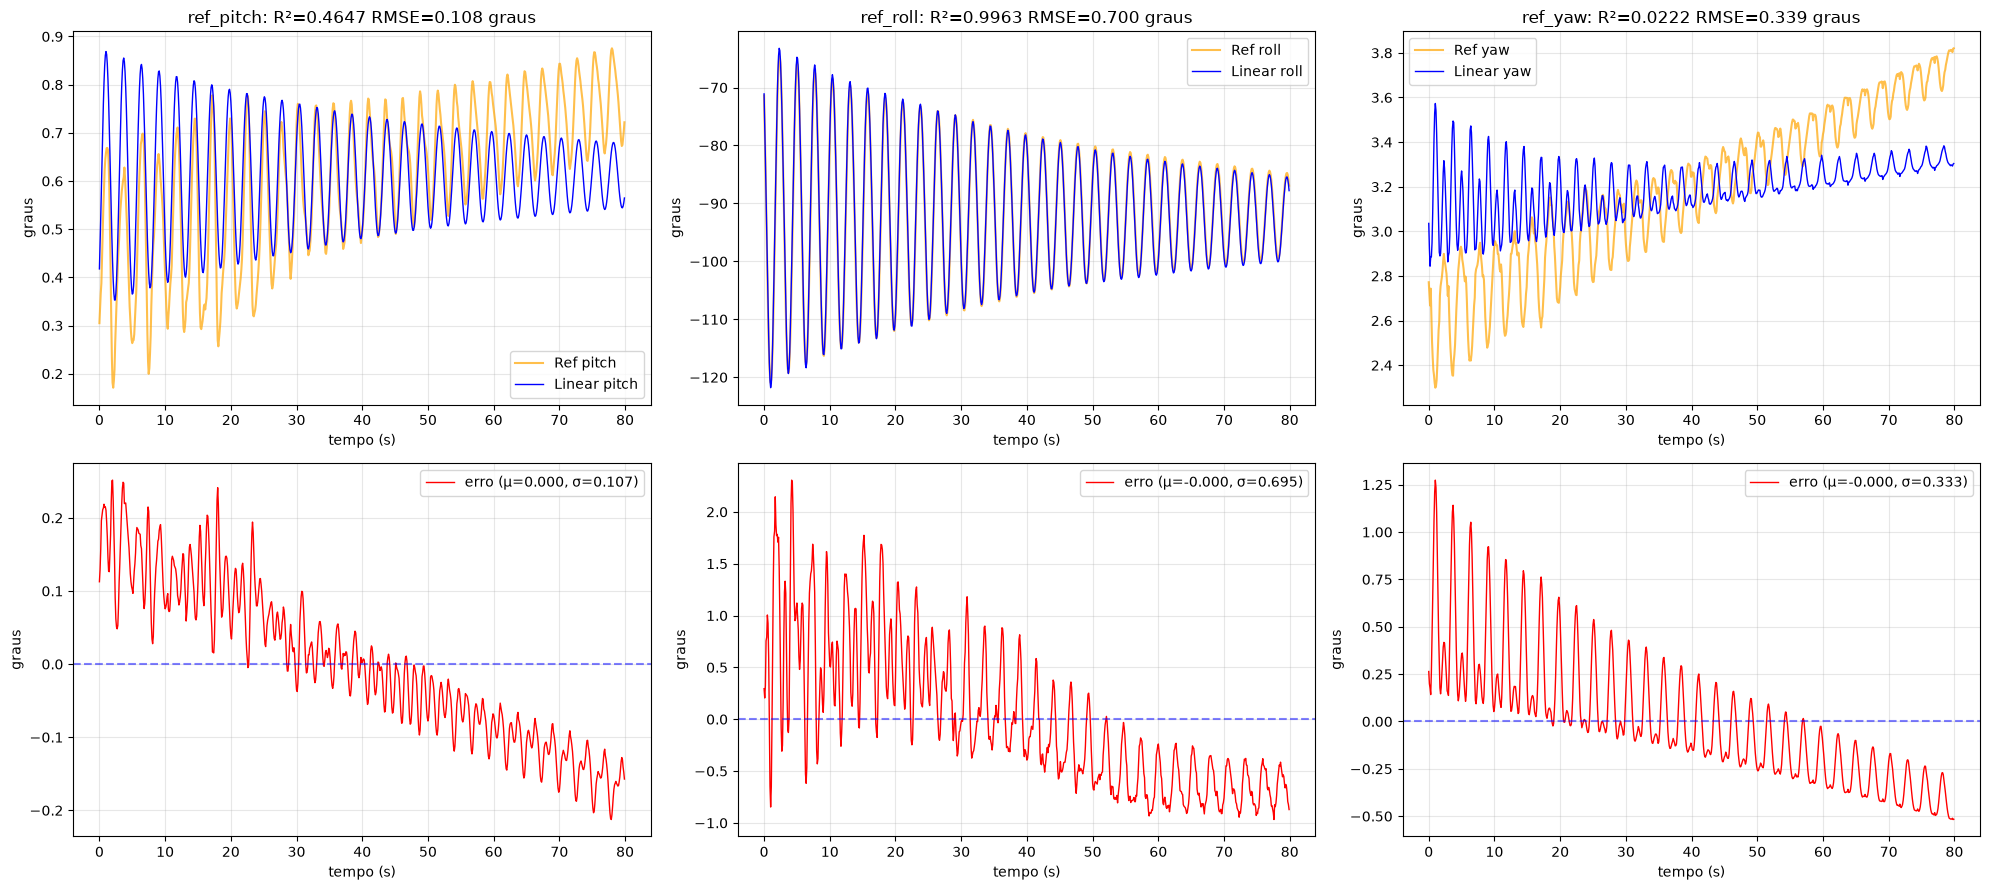

In [9]:
fit.display()
fit.plot()

# BACKUP DOS PARÂMETROS
- Cada linha de `params` é um ângulo da referência: $ref = pitch \cdot M_{pitch} + roll \cdot M_{roll} + yaw \cdot M_{yaw} + bias$

In [10]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('model_')]    # O target.csv TEMPORÁRIO TAMBÉM MORA NO Backup
index  = len(saved) + 1

output = f'Backup/model_{index}'
os.makedirs(output, exist_ok=True)

results = {
    'model':   'linear_fit',
    'fuse':    fit.fuse,
    'params':  fit.info(),
    'metrics': fit.get(),
    'K_CV':    LinearFit.K_CV,
    'dataset': {'path': SOURCE, 'samples': len(df), 'dt': float(dt), 'xCols': xCols, 'yCols': yCols}
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
print(output)
results

Backup/model_3


{'model': 'linear_fit',
 'fuse': False,
 'params': {'ref_pitch': {'pitch': -0.009221,
   'roll': 0.0,
   'yaw': 0.0,
   'bias': 0.583867},
  'ref_roll': {'pitch': 0.0, 'roll': 6.847054, 'yaw': 0.0, 'bias': -81.537613},
  'ref_yaw': {'pitch': 0.0, 'roll': 0.0, 'yaw': 0.535418, 'bias': 1.463621}},
 'metrics': {'ref_pitch': {'r2': 0.46468297974472045,
   'r2_adj': 0.46129489733804147,
   'rmse': 0.10828904140016675,
   'mae': 0.09049383151543906},
  'ref_roll': {'r2': 0.9962671982025716,
   'r2_adj': 0.9962435728747397,
   'rmse': 0.6996799266189334,
   'mae': 0.5792256786211972},
  'ref_yaw': {'r2': 0.022180674888955386,
   'r2_adj': 0.0159919449831893,
   'rmse': 0.33923030741610083,
   'mae': 0.26060331674444215}},
 'K_CV': 5,
 'dataset': {'path': '../../Dataset/test1/results/corrected.csv',
  'samples': 800,
  'dt': 0.1,
  'xCols': ['pitch', 'roll', 'yaw'],
  'yCols': ['ref_pitch', 'ref_roll', 'ref_yaw']}}

# SALVANDO A ATITUDE
- Ângulos calibrados ao lado dos da referência (`_ref`): `attitude.csv` é a entrada do `4 - Heave` e do `Analysis.ipynb`

In [11]:
attitude = full[['time', 'static']].copy()
yModel   = full[xCols].to_numpy() @ fit.M.T + fit.B    # O AJUSTE APLICADO TAMBÉM AO REPOUSO, QUE A ANÁLISE PRECISA

for i, xCol in enumerate(xCols):
    attitude[xCol]          = yModel[:, i]
    attitude[f'{xCol}_ref'] = full[yCols[i]]

record = {
    'strategy': results['model'],
    'backup':   f'3 - Attitude/LinearFit/{output}',
    'targets':  xCols,
    'metrics':  fit.get()
}

os.makedirs(RESULTS, exist_ok=True)
attitude.to_csv(f'{RESULTS}/attitude.csv', index=None)
pd.Series(record).to_json(f'{RESULTS}/attitude.json', indent=4)
print(f'{RESULTS}/attitude.csv')
attitude

../../Dataset/test1/results/attitude.csv


,time,static,pitch,pitch_ref,roll,roll_ref,yaw,yaw_ref
0,0.0,False,0.417500,0.304871,-71.095855,-71.390541,3.035610,2.771970
1,0.1,False,0.466471,0.337243,-76.457099,-76.661753,2.922636,2.723841
2,0.2,False,0.523140,0.366750,-82.352413,-82.677810,2.843930,2.667691
3,0.3,False,0.584015,0.387721,-88.453139,-89.209529,2.885157,2.743322
4,0.4,False,0.646373,0.442381,-95.122170,-95.913135,2.885692,2.624720
...,...,...,...,...,...,...,...,...
1795,279.4,True,0.607011,1.644962,-90.904384,-92.131613,4.295449,6.371291
1796,279.5,True,0.607002,1.645535,-90.904384,-92.131613,4.295449,6.371291
1797,279.6,True,0.606974,1.644962,-90.897537,-92.131613,4.296520,6.371291
1798,279.7,True,0.606974,1.645535,-90.897537,-92.131613,4.295449,6.377020


# EXPORTANDO PARA O FIRMWARE
- `config.h` do modelo leva a matriz e o viés; o `config.h` do `attitude` diz qual modelo o firmware compila
- Quem exportar por último é quem roda no MRU, do mesmo jeito que o `attitude.csv` do teste

In [12]:
FIRMWARE = '../../../Hardware/Embedded/Main/objects/processing/attitude'
STAMP    = f'{datetime.date.today():%d/%m/%Y}'

matrix = ',\n\t'.join('{' + ', '.join(f'{value:.8f}f' for value in row) + '}' for row in fit.M)
bias   = ', '.join(f'{value:.8f}f' for value in fit.B)

header = f'''#ifndef LINEAR_CONFIG_H
#define LINEAR_CONFIG_H

// GERADO POR Calibration/3 - Attitude/LinearFit/1 - Model.ipynb EM {STAMP}
#define LINEAR_NAME "linear_fit"

static const float LINEAR_M[3][3] = {{
\t{matrix}
}};    // linha = angulo calibrado, coluna = angulo do sensor: {', '.join(xCols)}

static const float LINEAR_B[3] = {{{bias}}};

#endif
'''

select = f'''#ifndef ATTITUDE_CONFIG_H
#define ATTITUDE_CONFIG_H
#include "linear/index.h"

// GERADO POR Calibration/3 - Attitude/LinearFit/1 - Model.ipynb EM {STAMP}
using AttitudeModel = LinearModel;

#endif
'''

open(f'{FIRMWARE}/linear/config.h', 'w').write(header)
open(f'{FIRMWARE}/config.h', 'w').write(select)

print(f'{FIRMWARE}/linear/config.h')
print(header)

../../../Hardware/Embedded/Main/objects/processing/attitude/linear/config.h
#ifndef LINEAR_CONFIG_H
#define LINEAR_CONFIG_H

// GERADO POR Calibration/3 - Attitude/LinearFit/1 - Model.ipynb EM 15/10/2026
#define LINEAR_NAME "linear_fit"

static const float LINEAR_M[3][3] = {
	{-0.00922058f, 0.00000000f, 0.00000000f},
	{0.00000000f, 6.84705448f, 0.00000000f},
	{0.00000000f, 0.00000000f, 0.53541830f}
};    // linha = angulo calibrado, coluna = angulo do sensor: pitch, roll, yaw

static const float LINEAR_B[3] = {0.58386718f, -81.53761347f, 1.46362145f};

#endif

